# Simulated Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import anndata

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
def load_mHy(info_file, cnts_file, section_id):

    # section id = '0.26', '0.21', '0.16', '0.11', '0.06', '0.01', '-0.04', '-0.09', '-0.14', '-0.19', '-0.24', '-0.29' 12 in total
    # cluster =     15      15      14      15      15      15      14       15       15       15      16        15
    # 9 clusters: ['BST' 'MPA' 'MPN' 'PV' 'PVH' 'PVT' 'V3' 'fx'] n_obs × n_vars = 5488 × 155
    xls_cnts = pd.ExcelFile(cnts_file)
    # print(xls_cnts.sheet_names)

    df_cnts = pd.read_excel(xls_cnts, section_id)
    xls_info = pd.ExcelFile(info_file)
    df_info = pd.read_excel(xls_info, section_id)
    # print(df_cnts, df_info)
    spatial_X = df_info.to_numpy()
    obs_ = df_info
    if len(df_info.columns) == 5:
        obs_.columns = ['psuedo_barcodes', 'x', 'y', 'original_clusters', 'Neuron_cluster_ID']
    elif len(df_info.columns) == 6:
        obs_.columns = ['psuedo_barcodes', 'x', 'y', 'cell_types', 'Neuron_cluster_ID', 'original_clusters']
    obs_.index = obs_['psuedo_barcodes'].tolist()
    # print(obs_)

    var_ = df_cnts.iloc[:, 0]
    var_ = pd.DataFrame(var_)
    # print(var_)

    ad = anndata.AnnData(X=df_cnts.iloc[:,1:].T, obs=obs_, var=var_)
    spatial = np.vstack((ad.obs['x'].to_numpy(), ad.obs['y'].to_numpy()))
    ad.obsm['spatial'] = spatial.T
    return ad

In [3]:
info_file = '/hpc/group/hickeylab/fl135/pkl_data/MERFISH_Animal1_info.xlsx'
cnts_file = '/hpc/group/hickeylab/fl135/pkl_data/MERFISH_Animal1_cnts.xlsx'

section_id = '-0.19' #, '-0.09', '-0.14', '-0.19', '-0.24'
ad_target = load_mHy(info_file, cnts_file, section_id)

section_id = '-0.14'
ad = load_mHy(info_file, cnts_file, section_id)


In [4]:
# print(ad_.X)             # Gene expression matrix
print(ad.obs['original_clusters'].unique())  # Spatial coordinates
print(ad_target)  # Spatial coordinates

['MPA' 'BST' 'fx' 'PVH' 'MPN' 'PVT' 'PV' 'V3']
AnnData object with n_obs × n_vars = 5803 × 155
    obs: 'psuedo_barcodes', 'x', 'y', 'cell_types', 'Neuron_cluster_ID', 'original_clusters'
    var: 'Unnamed: 0'
    obsm: 'spatial'


0 of 5803
5802 of 5803


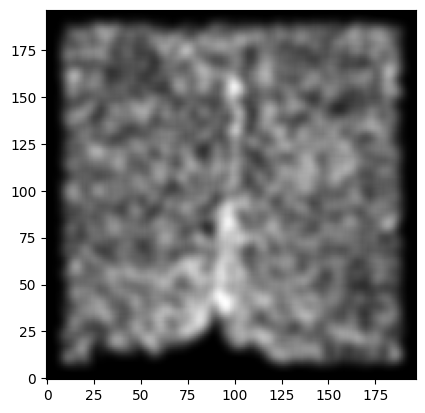

In [9]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J,fig = STalign.rasterize(x_target,y_target,dx=10, blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

0 of 5926
5925 of 5926


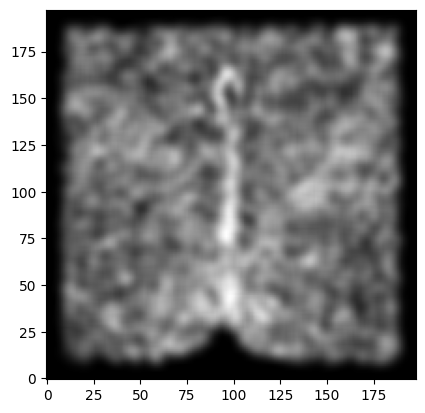

In [10]:
spatial_coords = ad.obsm['spatial']
x = spatial_coords[:, 0]
y = spatial_coords[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(x,y,dx=10, blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

In [11]:
x = x - 200
y = y + 3500

x_target = x_target - 4300
y_target = y_target + 3700

XI,YI,I = STalign.rasterize(x,y,dx=10,blur=1.5,draw=0)
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=10,blur=1.5,draw=0)

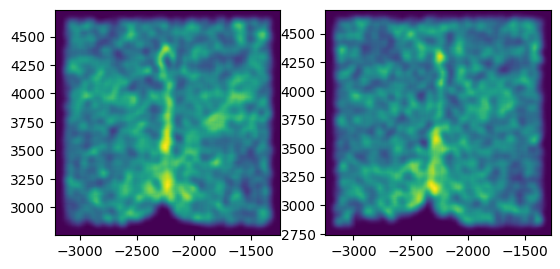

In [12]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow((I.transpose(1,2,0).squeeze()), extent=extentI)
ax[1].imshow((J.transpose(1,2,0).squeeze()), extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 12min 12s, sys: 14.2 s, total: 12min 26s
Wall time: 12min 5s


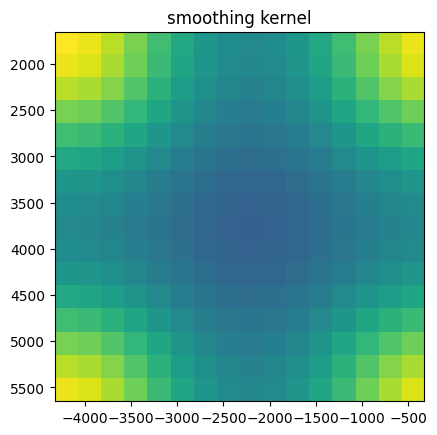

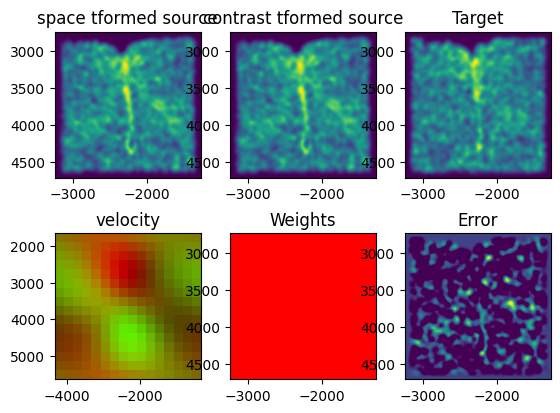

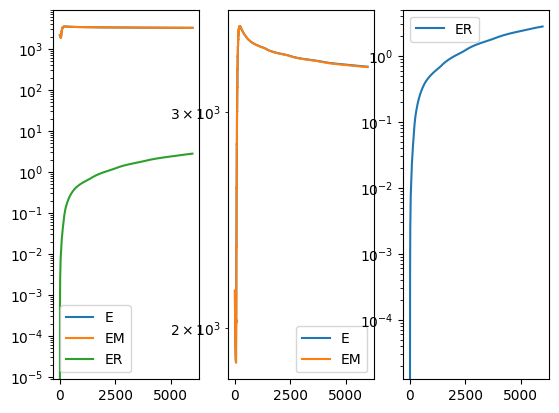

In [25]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            'niter': 6000,
            'device':device,
            'epV': 20,
            'sigmaA': 0.1, #standard deviation of artifact intensities
            'sigmaB': 0.1, #standard deviation of background intensities
            'sigmaM': 0.1, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [26]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']


In [27]:
pointsI = torch.tensor(np.stack([y, x], 1), device='cuda', dtype=torch.float64)

# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, pointsI)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

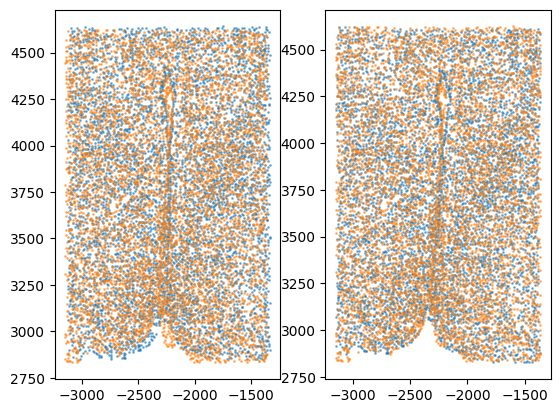

In [28]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

In [29]:
from sklearn.metrics import pairwise

f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)
alignment = pairwise.euclidean_distances(f1, f2)
alignment = np.exp(-alignment)

alignment_df = pd.DataFrame(alignment)


In [32]:
# Save as .pkl
alignment_df.to_pickle("-0.14_-0.19_AlignmentPi.pkl")

## LAA

In [30]:
def cal_layer_based_alignment_result_mHypothalamus(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    #l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    ir = 0
    max_smallerThan0 = []
    sum_smallerThan0 = []
    min_smallerThan0 = []
    '''
    cnt1 = 0
    cnt2 = 0
    cnt3 = 0
    cnt4 = 0
    cnt5 = 0
    cnt6 = 0
    '''
    for i, elem in enumerate(alignment):
        #if np.sum(elem)>0:
        if np.max(elem) - np.min(elem) != 0:
            if labels[i] == labels[elem.argmax() + alignment.shape[0]]:
                cnt0 += 1
            '''
            if labels[i] == '-1' or labels[elem.argmax() + alignment.shape[0]] == '-1':
                continue
            if l_dict[labels[i]] == l_dict[labels[elem.argmax() + alignment.shape[0]]]:
                cnt0 += 1

            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 1:
                cnt1 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 2:
                cnt2 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 3:
                cnt3 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 4:
                cnt4 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 5:
                cnt5 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 6:
                cnt6 += 1
          '''
        else:
            ir += 1
            max_smallerThan0.append(np.max(elem))
            sum_smallerThan0.append(np.sum(elem))
            min_smallerThan0.append(np.min(elem))
    print("the number of sum alignment equals 0:", str(cnt0))
    if len(sum_smallerThan0)>0:
        print("sum in sum alignment equals 0 is between", np.min(sum_smallerThan0), np.max(sum_smallerThan0))
        print("max in sum alignment equals 0 is between", np.min(max_smallerThan0), np.max(max_smallerThan0))
        print("min in sum alignment equals 0 is between", np.min(min_smallerThan0), np.max(min_smallerThan0))
    #print(alignment.shape[0])
    #print(cnt0/alignment.shape[0], cnt1/alignment.shape[0], cnt2/alignment.shape[0], cnt3/alignment.shape[0], cnt4/alignment.shape[0], cnt5/alignment.shape[0], cnt6/alignment.shape[0])
    #res.extend([cnt0/alignment.shape[0], cnt1/alignment.shape[0], cnt2/alignment.shape[0], cnt3/alignment.shape[0], cnt4/alignment.shape[0], cnt5/alignment.shape[0], cnt6/alignment.shape[0]])
    #res.extend([cnt0, cnt1, cnt2, cnt3, cnt4, cnt5, cnt6])
    res.extend([cnt0])
    return res

In [31]:
res = cal_layer_based_alignment_result_mHypothalamus(alignment, ad, ad_target)
res[0]/len(ad.obs['original_clusters'])

the number of sum alignment equals 0: 2649


0.4470131623354708

## ARI

In [33]:
from sklearn.metrics import adjusted_rand_score


def compute_alignment_ari(sliceA, sliceB, pi):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [34]:
ari = compute_alignment_ari(ad_target, ad, alignment)
ari

0.5626352397925523

## 3D

In [82]:
cmap = []
if len(unique_clusters) <= 10: # when no. of layers <=10
    for e in plt.get_cmap('tab10').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
else: # when 10< no. of layers <=40
    for e in plt.get_cmap('tab20').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
    for e in plt.get_cmap('tab20b').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))

# Create the dictionary with the combined clusters
c_dict = dict(zip(unique_clusters, cmap))
c_dict

{'BST': '#1f77b4',
 'MPA': '#ff7f0e',
 'MPN': '#2ca02c',
 'PV': '#d62728',
 'PVH': '#9467bd',
 'PVT': '#8c564b',
 'V3': '#e377c2',
 'fx': '#7f7f7f'}

In [35]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,-2914x-601,MPA
1,-2908x-509,MPA
2,-2904x-495,MPA
3,-2902x-540,MPA
4,-2893x-483,MPA


In [36]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 2
results1['slice'] = '-0.14'
results1

,index,original_clusters,X,Y,Z,slice
0,-2914x-601,MPA,-3146.237946,2914.493050,2,-0.14
1,-2908x-509,MPA,-3136.267669,3004.592302,2,-0.14
2,-2904x-495,MPA,-3131.998560,3018.945129,2,-0.14
3,-2902x-540,MPA,-3132.329155,2974.392374,2,-0.14
4,-2893x-483,MPA,-3121.209869,3030.893554,2,-0.14
...,...,...,...,...,...,...
5921,-1137x754,BST,-1368.985725,4218.887289,2,-0.14
5922,-1208x944,BST,-1429.074792,4412.018983,2,-0.14
5923,-1193x941,BST,-1415.032274,4408.414929,2,-0.14
5924,-1168x1137,fx,-1387.339278,4608.346577,2,-0.14


In [37]:
results1.to_csv("2.csv", index=False)